# How the Grover winner detector works

Tic-tac-toe has 8 winning lines. After every move from turn 5 on, this
project asks a quantum circuit "which line, if any, did the player who just
moved complete?" using one step of Grover's search, then checks only the
lines the circuit points at.

This notebook builds the circuit piece by piece and runs it on a perfect
simulator. `02_noise` adds realistic device noise and `03_hardware` runs it on
a real IBM device. `00_class_submission` is the original class version.

In [3]:
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit import QuantumRegister
from qiskit.quantum_info import Statevector

from qttt.backends import IdealBackend, get_backend
from qttt.board import EMPTY, LINE_NAMES, O, WIN_LINES, X, classical_winning_lines
from qttt.detector import DEFAULT_BUDGET, DEFAULT_SHOTS, binomial_cutoff, detect_winner
from qttt.encoding import encode_player_board, line_index_to_bitstring
from qttt.grover import build_search_circuit, diffuser
from qttt.noise import ideal_line_probabilities
from qttt.oracles import player_oracle
from qttt.stats import _binomial_pmf

SEED = 4903
_ = EMPTY
CASES = {
    "Single win": (X, O, X,
                   O, X, O,
                   _, _, X),
    "Double win": (X, X, X,
                   X, O, O,
                   X, O, O),
    "No win": (X, O, X,
               X, O, O,
               O, X, X),
}


def show(board):
    return "\n".join(" " + " | ".join(c if c != EMPTY else "." for c in board[r:r + 3]) for r in (0, 3, 6))


def line_probabilities(qc):
    """Exact probability of each line index, read from the statevector (no sampling)."""
    qc = qc.remove_final_measurements(inplace=False)
    line = qc.qregs[1]
    probs = Statevector(qc).probabilities([qc.find_bit(q).index for q in line])
    return probs

## 1. What is being searched: 8 lines

Each winning line gets an index 0–7, stored in 3 qubits. Grover's search runs
over these 8 indices, not over the board.

In [4]:
print(f"{'index':>5}  {'qubits':6}  {'cells':9}  line")
for i, cells in enumerate(WIN_LINES):
    print(f"{i:>5}  {line_index_to_bitstring(i):6}  {str(cells):9}  {LINE_NAMES[i]}")

index  qubits  cells      line
    0  000     (0, 1, 2)  top row
    1  001     (3, 4, 5)  middle row
    2  010     (6, 7, 8)  bottom row
    3  011     (0, 3, 6)  left column
    4  100     (1, 4, 7)  middle column
    5  101     (2, 5, 8)  right column
    6  110     (0, 4, 8)  diagonal (top-left to bottom-right)
    7  111     (2, 4, 6)  diagonal (top-right to bottom-left)


### When the check runs: turn 5 onward

A line needs three marks from the same player. X moves on turns 1, 3, 5, 7 and 9,
and O on turns 2, 4, 6 and 8, so the earliest anyone can complete a line is X's
third mark on turn 5 (O's earliest is turn 6). On turns 1–4 the answer is always
"no winner", so the game skips the check: running the circuit there could only
cost time and, under noise, add false flags.

From turn 5 on, the check runs after every move and asks only about the player
who just moved. The other player cannot have a line: if they had completed one
on an earlier turn, that check would already have ended the game. For the same
reason two lines at once can only be completed by a single move that finishes
both, which happens only on X's fifth mark on turn 9 — the double-win case.

Of the 5,478 positions reachable in a real game, the 4,388 from turn 5 on are
the ones the detector ever sees: 3,446 with no winner, 920 with one winning
line and 22 with two.

## 2. Loading the board: 13 qubits

Only the player who just moved can have a line, and the game knows who that
is. So each cell needs one qubit: |1⟩ if that player owns it, |0⟩ otherwise
(empty or the opponent's). With 3 line-index qubits and 1 phase qubit that is
13 qubits. (The class version used 2 qubits per cell to tell X and O apart:
22 qubits.)

Example: X has just moved and owns cells 0, 2, 4 and 8.

 X | O | X
 O | X | O
 . | . | X

qubits set to |1>: [0, 2, 4, 8]


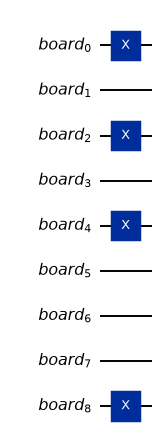

In [5]:
board = CASES["Single win"]
print(show(board), end="\n\n")
board_reg = QuantumRegister(9, "board")
encoder = QuantumCircuit(board_reg)
encode_player_board(encoder, board_reg, board, X)
print("qubits set to |1>:", [encoder.find_bit(i.qubits[0]).index for i in encoder.data])
encoder.draw("mpl", scale=0.7)

## 3. The oracle: flip the sign of winning lines

For each line i, the oracle temporarily flips the line-index qubits so that
index i reads as 111, then applies one multi-controlled X (MCX) with 6
controls: the 3 line-index qubits and the line's 3 cell qubits. Its target is
the phase qubit, prepared in |−⟩, so instead of flipping a bit the MCX flips
the *sign* of the state (phase kickback) when all 6 controls are 1. Net
effect: every line index the player owns gets a minus sign; nothing else
changes. 8 lines, 8 MCX gates.

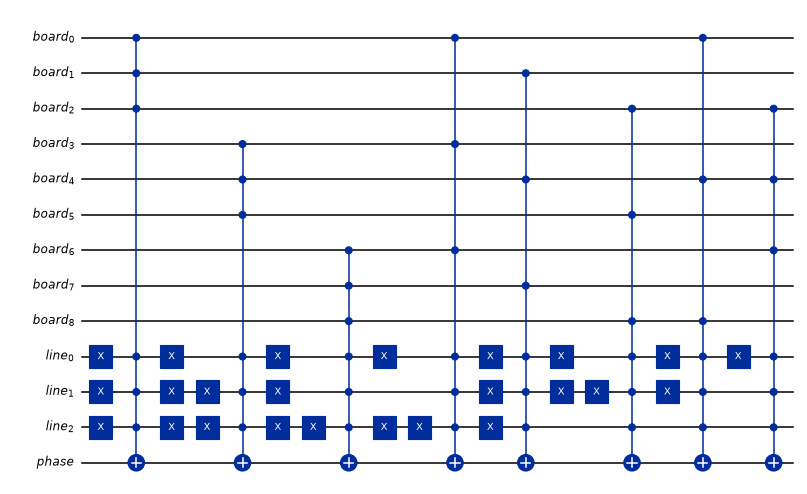

In [6]:
line_reg = QuantumRegister(3, "line")
phase_reg = QuantumRegister(1, "phase")
oracle = QuantumCircuit(board_reg, line_reg, phase_reg)
player_oracle(oracle, board_reg, line_reg, phase_reg[0])
oracle.draw("mpl", fold=40, scale=0.55)

Checking the effect: start from all 8 indices with equal amplitude, apply the
oracle, and read the sign of each index's amplitude.

In [7]:
qc = QuantumCircuit(board_reg, line_reg, phase_reg)
encode_player_board(qc, board_reg, board, X)
qc.x(phase_reg[0])
qc.h(phase_reg[0])
qc.h(line_reg)
qc.compose(oracle, inplace=True)
state = Statevector(qc)
signs = []
for i in range(8):
    # The basis state with this board, line index i and the phase qubit's |0> component.
    index = sum(1 << c for c in range(9) if board[c] == X) | (i << 9)
    signs.append(np.sign(state.data[index].real))
print("winning lines:", sorted(classical_winning_lines(board, X)))
print("sign of each line index after the oracle:", [int(s) for s in signs])

winning lines: [6]
sign of each line index after the oracle: [1, 1, 1, 1, 1, 1, -1, 1]


## 4. The diffuser: turn the sign into probability

A sign alone does not change what is measured. The diffuser reflects every
amplitude about the mean, which boosts the index with the flipped sign and
shrinks the rest.

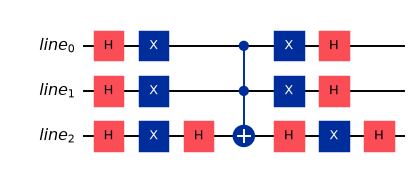

In [8]:
d = QuantumCircuit(line_reg)
diffuser(d, line_reg)
d.draw("mpl", scale=0.7)

## 5. The whole circuit

Load the board, put the line register in an equal superposition, one oracle,
one diffuser, measure the 3 line qubits.

13 qubits, 8 MCX gates


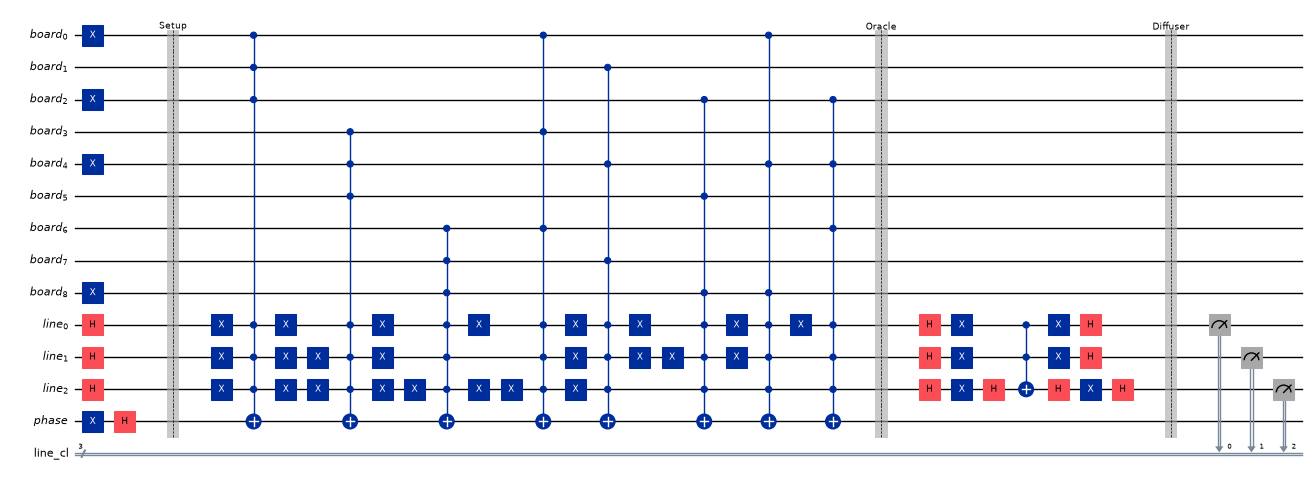

In [9]:
circuit = build_search_circuit("player", board, X)
print(f"{circuit.num_qubits} qubits, {circuit.count_ops().get('mcx', 0)} MCX gates")
circuit.draw("mpl", fold=45, scale=0.5)

## 6. Why exactly one Grover iteration

With M of 8 lines marked and sin θ = √(M/8), k iterations put sin²((2k+1)θ) on
the marked lines. A legal board has M = 0, 1 or 2.

iterations  M = 1 (each)  M = 2 (each)
         0         12.5%         12.5%
         1         78.1%         50.0%
         2         94.5%         12.5%
         3         33.0%         12.5%


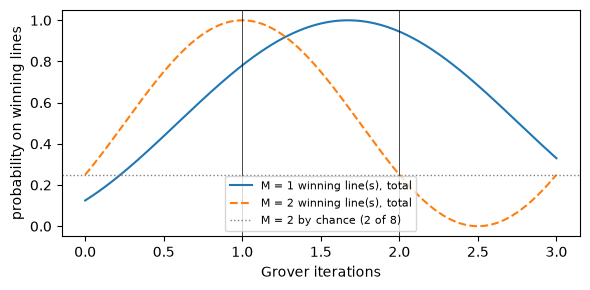

In [10]:
print(f"{'iterations':>10}  {'M = 1 (each)':>12}  {'M = 2 (each)':>12}")
for k in range(4):
    p1 = math.sin((2 * k + 1) * math.asin(math.sqrt(1 / 8))) ** 2
    p2 = math.sin((2 * k + 1) * math.asin(math.sqrt(2 / 8))) ** 2 / 2
    print(f"{k:>10}  {p1:>12.1%}  {p2:>12.1%}")

ks = np.linspace(0, 3, 300)
fig, ax = plt.subplots(figsize=(6, 3))
for m, style in ((1, "-"), (2, "--")):
    ax.plot(ks, np.sin((2 * ks + 1) * np.arcsin(np.sqrt(m / 8))) ** 2, style, label=f"M = {m} winning line(s), total")
ax.axhline(2 / 8, color="gray", linestyle=":", linewidth=1, label="M = 2 by chance (2 of 8)")
for k in (1, 2):
    ax.axvline(k, color="black", linewidth=0.5)
ax.set_xlabel("Grover iterations")
ax.set_ylabel("probability on winning lines")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

One iteration separates every case: 78% on a single winner, 50/50 on a
double win, flat 12.5% with no winner. Two iterations push a single winner to
94.5% but send a double win right back to 12.5% everywhere — indistinguishable
from no winner. The class version ran 2 iterations, so it missed double wins.
Reproducing that with the same oracle and diffuser:

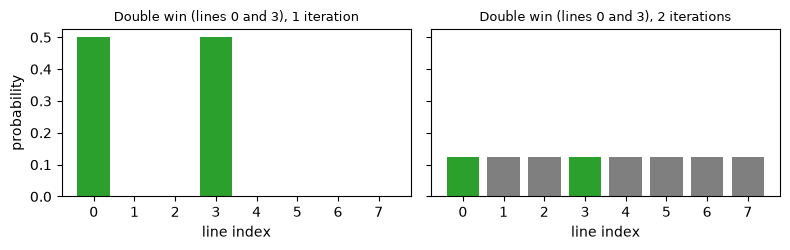

In [11]:
def search(board, player, iterations):
    board_reg = QuantumRegister(9, "board")
    line_reg = QuantumRegister(3, "line")
    phase_reg = QuantumRegister(1, "phase")
    qc = QuantumCircuit(board_reg, line_reg, phase_reg, ClassicalRegister(3, "line_cl"))
    encode_player_board(qc, board_reg, board, player)
    qc.x(phase_reg[0])
    qc.h(phase_reg[0])
    qc.h(line_reg)
    for _ in range(iterations):
        player_oracle(qc, board_reg, line_reg, phase_reg[0])
        diffuser(qc, line_reg)
    return qc


double = CASES["Double win"]
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, (1, 2)):
    probs = line_probabilities(search(double, X, k))
    ax.bar(range(8), probs, color=["tab:green" if i in (0, 3) else "tab:gray" for i in range(8)])
    ax.set_title(f"Double win (lines 0 and 3), {k} iteration{'s' if k > 1 else ''}", fontsize=9)
    ax.set_xticks(range(8))
    ax.set_xlabel("line index")
axes[0].set_ylabel("probability")
fig.tight_layout()
plt.show()

## 7. The three boards on a perfect simulator

Exact probabilities from the statevector, next to the theory.

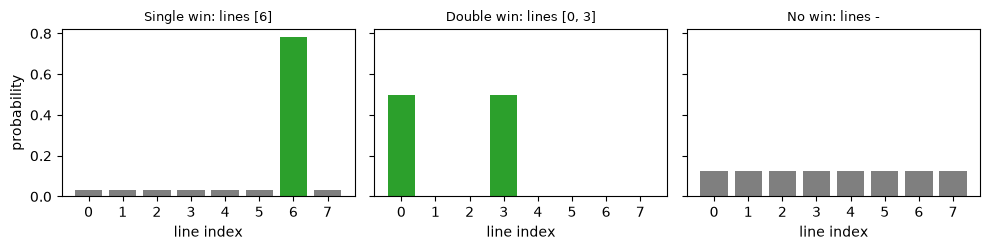

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, (name, board) in zip(axes, CASES.items()):
    winners = classical_winning_lines(board, X)
    probs = line_probabilities(build_search_circuit("player", board, X))
    assert np.allclose(probs, ideal_line_probabilities(winners))
    ax.bar(range(8), probs, color=["tab:green" if i in winners else "tab:gray" for i in range(8)])
    ax.set_title(f"{name}: lines {sorted(winners) or '-'}", fontsize=9)
    ax.set_xticks(range(8))
    ax.set_xlabel("line index")
axes[0].set_ylabel("probability")
fig.tight_layout()
plt.show()

## 8. From counts to a verdict

A real run gives counts, not probabilities: 1024 shots, each landing on one
line index. A line is *flagged* when its count reaches a cutoff, and each
flagged line is checked on the board (3 cell lookups). A confirmed line is
always a real win, so noise can make the detector miss a win but never invent
one.

The cutoff is set by a **check budget**: on a board with no winner each line
gets 1/8 of the shots on average, and the cutoff is the lowest count at which
the expected number of falsely flagged lines per round is at most 0.1. At 1024
shots that is 153 (14.9%).

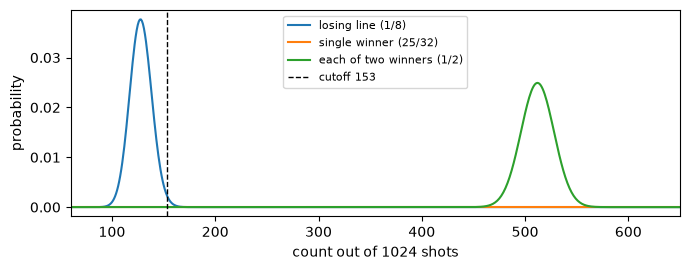

Single win  counts (51, 28, 31, 37, 29, 27, 792, 29)
            flagged [6], confirmed [6], rejected [] -> winner X, classical checks 1
Double win  counts (517, 0, 0, 507, 0, 0, 0, 0)
            flagged [0, 3], confirmed [0, 3], rejected [] -> winner X, classical checks 2
No win      counts (147, 116, 121, 133, 139, 130, 130, 108)
            flagged [], confirmed [], rejected [] -> winner None, classical checks 0


In [13]:
shots = DEFAULT_SHOTS
cutoff = binomial_cutoff(shots, DEFAULT_BUDGET)
ks = np.arange(0, 650)
fig, ax = plt.subplots(figsize=(7, 2.8))
for p, label in ((1 / 8, "losing line (1/8)"), (25 / 32, "single winner (25/32)"), (1 / 2, "each of two winners (1/2)")):
    ax.plot(ks, [_binomial_pmf(int(k), shots, p) for k in ks], label=label)
ax.axvline(cutoff, color="black", linestyle="--", linewidth=1, label=f"cutoff {cutoff}")
ax.set_xlim(60, 650)
ax.set_xlabel(f"count out of {shots} shots")
ax.set_ylabel("probability")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for name, board in CASES.items():
    r = detect_winner(board, player=X, shots=shots, backend=IdealBackend(seed=SEED))
    print(f"{name:11} counts {r.run.counts}")
    print(f"{'':11} flagged {list(r.candidates)}, confirmed {sorted(r.lines)}, rejected {list(r.rejected)}"
          f" -> winner {r.winner}, classical checks {r.checks}")

## 9. 22 qubits vs 13 qubits

The oracle is the expensive part. A real device has no 6- or 9-control gate,
so the compiler rewrites every MCX into one- and two-qubit gates and adds
swaps to move qubits next to each other. Two-qubit gates are where most errors
happen. Compiled for `fake_kingston` (a snapshot of one of the devices on IBM's
free plan):

In [14]:
kingston = get_backend("fake_kingston", seed=SEED)
print(f"{'version':9} {'qubits':>6} {'MCX':>4} {'controls':>8} {'2-qubit gates':>14} {'ESP':>7}")
for variant, qubits, mcx, controls in (("full", 22, 16, 9), ("player", 13, 8, 6)):
    m = kingston.metrics(kingston.search_template(variant))
    print(f"{variant:9} {qubits:>6} {mcx:>4} {controls:>8} {m.two_qubit_gates:>14} {10 ** m.log10_esp:>7.1%}")

version   qubits  MCX controls  2-qubit gates     ESP
full          22   16        9           2765    0.3%
player        13    8        6            750   27.0%


ESP (estimated success probability) multiplies (1 − error) over every gate:
roughly the chance that no gate fails. The 22-qubit circuit has essentially no
chance; the 13-qubit circuit keeps enough signal to work, as `02_noise` shows.

## 10. Why quantum? (Honestly)

Checking all 8 lines classically takes 24 cell lookups and no qubits. This
circuit needs hundreds of noisy two-qubit gates to point at the right line, so
it is not faster or cheaper. Tic-tac-toe has no "hard to find, easy to check"
gap for Grover to exploit, and 8 items is far too few for its √N speedup to
matter.

What it is good for is learning and measuring: the full Grover pipeline
(encoding, oracle, diffuser, measurement, classical verification) on a problem
small enough to check every case, and a clean test of how much signal survives
on today's hardware.